In [92]:
import numpy as np
import pandas as pd

#modelling`
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import max_error, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Lasso
from math import degrees
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor

#dummy modelling
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    max_error,
    mean_absolute_percentage_error
)


# plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline


In [ ]:
#drop features, use eda_df since we're using a pipeline that will impute missing values
eda_df = pd.read_csv("eda_df.csv")
eda_df = eda_df.drop(columns=['Z', 'N'])
eda_df.head()

,element,A,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
0,H,3,2.000000,18.5906,NaN,6257.233,NaN,8.589715
1,HE,6,2.000000,3505.2200,NaN,1710.000,NaN,-0.093288
2,BE,7,0.750000,NaN,-1587.13,10677.000,5606.85,6.662589
3,HE,8,3.000000,10663.8800,NaN,2535.000,NaN,-0.924088
4,LI,8,1.666667,16004.1300,NaN,2032.620,12416.00,-0.075772


In [ ]:
#splitting: uses a random split since the data is not skewed 
df_train, df_test = train_test_split(
    eda_df,
    test_size=0.2,  # 20% for testing
    random_state=42  # Ensure reproducibility
)
print(df_train.shape)
df_train.head()

features = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

TARGET = df_train['log_half_life'].name

def get_regression_metrics(model, X, y_true):

    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)
    mape = mean_absolute_percentage_error(y_true, y_predicted)

    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'max_error': maximum_error,
        'mape': mape,
        'r^2': r2_score(y_true, y_predicted)
    }

    return metrics_dict

(2236, 8)


In [77]:
#baseline model using a mean dummy regressor 
dummyregressor_mean = make_pipeline(
    SimpleImputer(strategy='median'),
    DummyRegressor(strategy='mean')
)

dummyregressor_mean.fit(df_train[features], df_train[TARGET])

dummyregressor_mean_results_train = get_regression_metrics(
    dummyregressor_mean,
    df_train[features],
    df_train[TARGET]
)

# Testing results
dummyregressor_mean_results_test = get_regression_metrics(
    dummyregressor_mean,
    df_test[features],
    df_test[TARGET]
)

# Create dataframe
dummyregressor_mean_results_df = pd.DataFrame(
    [dummyregressor_mean_results_train, dummyregressor_mean_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
dummyregressor_mean_results_df = dummyregressor_mean_results_df.round(4)

# Display dataframe
display(dummyregressor_mean_results_df)

,mae,mse,max_error,mape,r^2
Train,2.4027,10.2367,20.5202,1.191292e+13,0.0000
Test,2.4571,10.4488,11.1946,1.889300e+00,-0.0066


In [79]:
#baseline model using a median dummy regressor 
dummyregressor_median = make_pipeline(
    SimpleImputer(strategy='median'),
    DummyRegressor(strategy='median')
)

dummyregressor_median.fit(df_train[features], df_train[TARGET])

dummyregressor_median_results_train = get_regression_metrics(
    dummyregressor_median,
    df_train[features],
    df_train[TARGET]
)

# Testing results
dummyregressor_median_results_test = get_regression_metrics(
    dummyregressor_median,
    df_test[features],
    df_test[TARGET]
)

# Create dataframe
dummyregressor_median_results_df = pd.DataFrame(
    [dummyregressor_median_results_train, dummyregressor_median_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
dummyregressor_median_results_df = dummyregressor_median_results_df.round(4)

# Display dataframe
display(dummyregressor_median_results_df)


,mae,mse,max_error,mape,r^2
Train,2.4017,10.2453,20.4271,1.097592e+13,-0.0008
Test,2.4515,10.4088,11.2876,1.796900e+00,-0.0027


In [82]:
#linear model pipline
linear_model = make_pipeline(
    SimpleImputer(strategy=('median')), StandardScaler(), LinearRegression())

linear_model.fit(df_train[features],df_train[TARGET])
linear_model_results_train = get_regression_metrics(linear_model, df_train[features], df_train[TARGET])
linear_model_results_test = get_regression_metrics(linear_model, df_test[features], df_test[TARGET])

# Create dataframe
linear_model_results_df = pd.DataFrame(
    [linear_model_results_train, linear_model_results_test],
    index=['Train', 'Test']
)
# Round to 4 decimal places
linear_model_results_df = linear_model_results_df.round(4)

# Display dataframe
display(linear_model_results_df)

,mae,mse,max_error,mape,r^2
Train,2.2496,9.3905,21.6658,1.738959e+13,0.0827
Test,2.2752,9.3797,10.5062,1.923300e+00,0.0964


In [83]:
ridge_model = make_pipeline(
    SimpleImputer(strategy=('median')),
    StandardScaler(),
    Ridge(alpha=1.0)
)
ridge_model.fit(df_train[features],df_train[TARGET])
ridge_model_results_train = get_regression_metrics(ridge_model, df_train[features], df_train[TARGET])
ridge_model_results_test = get_regression_metrics(ridge_model, df_test[features], df_test[TARGET])

ridge_model_results_df = pd.DataFrame(
    [ridge_model_results_train, ridge_model_results_test],
    index=['Train', 'Test']
)
# Round to 4 decimal places
ridge_model_results_df = ridge_model_results_df.round(4)

# Display dataframe
display(ridge_model_results_df)

,mae,mse,max_error,mape,r^2
Train,2.2496,9.3905,21.6625,1.738048e+13,0.0827
Test,2.2752,9.3799,10.5069,1.923000e+00,0.0964


In [84]:
lasso_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=10000)
)

lasso_model.fit(df_train[features],df_train[TARGET])
lasso_model_results_train = get_regression_metrics(lasso_model, df_train[features], df_train[TARGET])
lasso_model_results_test = get_regression_metrics(lasso_model, df_test[features], df_test[TARGET])

lasso_model_results_df = pd.DataFrame(
    [lasso_model_results_train, lasso_model_results_test],
    index=['Train', 'Test']
)
# Round to 4 decimal places
lasso_model_results_df = lasso_model_results_df.round(4)

# Display dataframe
display(lasso_model_results_df)

,mae,mse,max_error,mape,r^2
Train,2.2813,9.5936,20.9274,1.444410e+13,0.0628
Test,2.3126,9.6267,10.7227,1.860600e+00,0.0726


In [ ]:
#testing various polynomial degrees
polynomial_results = []

for degree in [2,3,4]:
    polynomial_model = make_pipeline(
        SimpleImputer(strategy='median'),
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    polynomial_model.fit(df_train[features],df_train[TARGET])
    polynomial_model_results_train = get_regression_metrics(polynomial_model, df_train[features], df_train[TARGET])
    polynomial_model_results_test = get_regression_metrics(polynomial_model, df_test[features], df_test[TARGET])

    polynomial_results.append({
    "Degree": degree,

    **{f"Train {k.upper()}": v
       for k, v in polynomial_model_results_train.items()},

    **{f"Test {k.upper()}": v
       for k, v in polynomial_model_results_test.items()}
})


polynomial_results_df = pd.DataFrame(polynomial_results)
polynomial_results_df = polynomial_results_df.round(4)
polynomial_results_df





,Degree,Train MAE,Train MSE,Train MAX_ERROR,Train MAPE,Train R^2,Test MAE,Test MSE,Test MAX_ERROR,Test MAPE,Test R^2
0,2,1.8147,6.6063,11.4886,1.334444e+13,0.3546,1.8998,7.1018,11.4517,1.8799,0.3158
1,3,1.4013,4.3032,9.4722,8.457996e+12,0.5796,1.5190,5.0474,9.3652,1.2432,0.5138
2,4,1.1239,2.6931,9.0713,7.779314e+12,0.7369,1.5822,22.8902,90.6189,1.4997,-1.2051


In [85]:
#using a polynomial model with degree 3
polynomial_deg3_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

polynomial_deg3_model.fit(df_train[features],df_train[TARGET])
polynomial_deg3_results_train = get_regression_metrics(polynomial_deg3_model, df_train[features], df_train[TARGET])
polynomial_deg3_results_test = get_regression_metrics(polynomial_deg3_model, df_test[features], df_test[TARGET])

polynomial_deg3_results_df = pd.DataFrame(
    [polynomial_deg3_results_train, polynomial_deg3_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
polynomial_deg3_results_df = polynomial_deg3_results_df.round(4)

# Display dataframe
display(polynomial_deg3_results_df)

,mae,mse,max_error,mape,r^2
Train,1.4013,4.3032,9.4722,8.457996e+12,0.5796
Test,1.5190,5.0474,9.3652,1.243200e+00,0.5138


In [86]:
#Kernel Ridge Regression
krr_model = make_pipeline(
    SimpleImputer(strategy=('median')),
    StandardScaler(),
    KernelRidge(alpha=1.0, kernel='rbf', gamma = 0.1, degree=3)
)

krr_model.fit(df_train[features],df_train[TARGET])

krr_model_results_train = get_regression_metrics(krr_model, df_train[features], df_train[TARGET])
krr_model_results_test = get_regression_metrics(krr_model, df_test[features], df_test[TARGET])

krr_model1_results_df = pd.DataFrame(
    [krr_model_results_train, krr_model_results_test],
    index=['Train', 'Test']
)
# Round to 4 decimal places
krr_model1_results_df = krr_model1_results_df.round(4)

# Display dataframe
display(krr_model1_results_df)


,mae,mse,max_error,mape,r^2
Train,1.3118,4.0270,11.5897,1.126081e+13,0.6066
Test,1.3576,4.3304,8.2155,1.136900e+00,0.5828


In [87]:
#Kernel Ridge Regression with GridSearchCV for hyperparameter tuning

# Define the parameter grid and the grid search object
param_grid = {
                'standardscaler': [MinMaxScaler(), StandardScaler()], # test different scaling methods
                'kernelridge__alpha': [0.1, 1.0, 10.0, 100.0, 1000.0], # test different regularization strengths
            }

grid_ridge = GridSearchCV(krr_model, param_grid=param_grid,
                          cv=5, scoring='neg_mean_absolute_error', verbose=1, n_jobs=2)

grid_ridge.fit(df_train[features], df_train[TARGET])

print("Best parameters:", grid_ridge.best_params_)
print("Best CV MAE:", -grid_ridge.best_score_)


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'kernelridge__alpha': 0.1, 'standardscaler': StandardScaler()}
Best CV MAE: 1.2035895262932006


In [104]:
#updated kernal ridge regression model using an alpha value of 0.1
krr_model2 = make_pipeline(
    SimpleImputer(strategy=('median')),
    StandardScaler(),
    KernelRidge(alpha=0.1, kernel='rbf', gamma = 0.1, degree=3)
)

krr_model2.fit(df_train[features],df_train[TARGET])
krr_model2_results_train = get_regression_metrics(krr_model2, df_train[features], df_train[TARGET])
krr_model2_results_test = get_regression_metrics(krr_model2, df_test[features], df_test[TARGET])

krr_model2_results_df = pd.DataFrame(
    [krr_model2_results_train, krr_model2_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
krr_model2_results_df = krr_model2_results_df.round(4)

# Display dataframe
display(krr_model2_results_df)

,mae,mse,max_error,mape,r^2
Train,1.0883,2.6864,8.1609,7.944318e+12,0.7376
Test,1.1654,3.0887,8.7122,1.115500e+00,0.7024


In [ ]:

xgb_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
)

xgb_model.fit(df_train[features], df_train[TARGET])
xgb_model_results_train = get_regression_metrics(xgb_model, df_train[features], df_train[TARGET])
xgb_model_results_test = get_regression_metrics(xgb_model, df_test[features], df_test[TARGET])

xgb_model_results_df = pd.DataFrame(
    [xgb_model_results_train, xgb_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
xgb_model_results_df = xgb_model_results_df.round(4)

# Display dataframe
display(xgb_model_results_df)

,mae,mse,max_error,mape,r^2
Train,0.9902,2.0779,9.6431,5.610105e+12,0.7970
Test,1.1677,2.8306,6.4734,1.070700e+00,0.7273


In [ ]:
xgb_model = make_pipeline(
    SimpleImputer(strategy='median'),
    XGBRegressor(
        objective='reg:squarederror',
        random_state=42
    )
)
param_grid_xgb = {
    'xgbregressor__n_estimators': [100, 200, 300],
    'xgbregressor__max_depth': [2, 3, 5],
    'xgbregressor__learning_rate': [0.01, 0.05, 0.1],
    'xgbregressor__subsample': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid_xgb,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    verbose=1
)

# Fit grid search
xgb_grid.fit(
    df_train[features],
    df_train[TARGET]
)

# Display optimal parameters
print("Best parameters:", xgb_grid.best_params_)
print("Best CV MAE:", -xgb_grid.best_score_)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters: {'xgbregressor__learning_rate': 0.1, 'xgbregressor__max_depth': 5, 'xgbregressor__n_estimators': 300, 'xgbregressor__subsample': 0.8}
Best CV MAE: 0.9279224165515801


In [102]:
#updated XGBoost model
xgb_model2 = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=5, random_state=42)
)

xgb_model2.fit(df_train[features], df_train[TARGET])
xgb_model_results_train = get_regression_metrics(xgb_model2, df_train[features], df_train[TARGET])
xgb_model_results_test = get_regression_metrics(xgb_model2, df_test[features], df_test[TARGET])

xgb_model2_results_df = pd.DataFrame(
    [xgb_model_results_train, xgb_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
xgb_model2_results_df = xgb_model2_results_df.round(4)

# Display dataframe
display(xgb_model2_results_df)
    

,mae,mse,max_error,mape,r^2
Train,0.3313,0.2355,3.1463,3.228302e+12,0.9770
Test,0.9149,2.0899,8.1399,7.512000e-01,0.7987


In [ ]:

random_forest_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    )
)

random_forest_model.fit(df_train[features], df_train[TARGET])

rf_model_results_train = get_regression_metrics(random_forest_model, df_train[features], df_train[TARGET])
rf_model_results_test = get_regression_metrics(random_forest_model, df_test[features], df_test[TARGET])

rf_model2_results_df = pd.DataFrame(
    [rf_model_results_train, rf_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
rf_model2_results_df = rf_model2_results_df.round(4)

# Display dataframe
display(rf_model2_results_df)

Random Forest Results (Train): {'mae': 0.3414207205382388, 'mse': 0.31644681999195057, 'max_error': 6.1832005579685685, 'mape': 1672874263146.8855, 'r^2': 0.9690869901292163}
Random Forest Results (Test): {'mae': 0.9116367078188683, 'mse': 2.0391467175104587, 'max_error': 6.936327465130817, 'mape': 0.6715926245619022, 'r^2': 0.8035575623904146}


,mae,mse,max_error,mape,r^2
Train,0.3414,0.3164,6.1832,1.672874e+12,0.9691
Test,0.9116,2.0391,6.9363,6.716000e-01,0.8036


In [64]:
param_grid_rf = {
    'randomforestregressor__n_estimators': [100, 200, 300],
    'randomforestregressor__max_depth': [None, 10, 20, 30],
    'randomforestregressor__min_samples_split': [2, 5, 10],
    'randomforestregressor__min_samples_leaf': [1, 2, 4]
}

rf_grid = GridSearchCV(
    estimator=random_forest_model,
    param_grid=param_grid_rf,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(
    df_train[features],
    df_train[TARGET]
)

print("Best parameters:", rf_grid.best_params_)
print("Best CV MAE:", -rf_grid.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'randomforestregressor__max_depth': 20, 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__min_samples_split': 2, 'randomforestregressor__n_estimators': 300}
Best CV MAE: 0.9555228033171828


In [106]:
#updated random forest model
random_forest_model2 = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    )
)

random_forest_model2.fit(df_train[features], df_train[TARGET])
rf_model2_results_train = get_regression_metrics(random_forest_model2, df_train[features], df_train[TARGET])
rf_model2_results_test = get_regression_metrics(random_forest_model2, df_test[features], df_test[TARGET])

rf_model2_results_df = pd.DataFrame(
    [rf_model2_results_train, rf_model2_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
rf_model2_results_df = rf_model2_results_df.round(4)

# Display dataframe
display(rf_model2_results_df)



,mae,mse,max_error,mape,r^2
Train,0.3465,0.3200,6.1109,1.601562e+12,0.9687
Test,0.9061,2.0023,6.9156,6.657000e-01,0.8071


In [95]:
#k nearest neighbours model

knn_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5)
)

knn_model.fit(df_train[features], df_train[TARGET])
knn_model_results_train = get_regression_metrics(knn_model, df_train[features], df_train[TARGET])
knn_model_results_test = get_regression_metrics(knn_model, df_test[features], df_test[TARGET])

knn_model_results_df = pd.DataFrame(
    [knn_model_results_train, knn_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
knn_model_results_df = knn_model_results_df.round(4)

# Display dataframe
display(knn_model_results_df)

,mae,mse,max_error,mape,r^2
Train,0.8714,1.9605,14.6171,3.889131e+12,0.8085
Test,1.0366,2.3886,7.8151,9.492000e-01,0.7699


In [100]:
# Create a dataframe containing all model results for testing set
all_results_test_df = pd.DataFrame({
    'DummyClassifier (Mean)': dummyregressor_mean_results_df.loc['Test'],
    'DummyClassifier (Median)': dummyregressor_median_results_df.loc['Test'],
    'Linear Model': linear_model_results_df.loc['Test'],
    'Ridge Model': ridge_model_results_df.loc['Test'],
    'Lasso Model': lasso_model_results_df.loc['Test'],
    'Polynomial Degree 3': polynomial_deg3_results_df.loc['Test'],
    'Kernel Ridge Regression': krr_model2_results_df.loc['Test'],
    'XGBoost': xgb_model2_results_df.loc['Test'],
    'Random Forest': rf_model2_results_df.loc['Test'],
    'K Nearest Neighbors': knn_model_results_df.loc['Test']
})

all_results_test_df = all_results_test_df.T  # Transpose for better readability
all_results_test_df = all_results_test_df.round(4)  # Round to 4 decimal places

display(all_results_test_df)


# Create a dataframe containing all model results
all_results_train_df = pd.DataFrame({
    'DummyClassifier (Mean)': dummyregressor_mean_results_df.loc['Train'],
    'DummyClassifier (Median)': dummyregressor_median_results_df.loc['Train'],
    'Linear Model': linear_model_results_df.loc['Train'],
    'Ridge Model': ridge_model_results_df.loc['Train'],
    'Lasso Model': lasso_model_results_df.loc['Train'],
    'Polynomial Degree 3': polynomial_deg3_results_df.loc['Train'],
    'Kernel Ridge Regression': krr_model2_results_df.loc['Train'],
    'XGBoost': xgb_model2_results_df.loc['Train'],
    'Random Forest': rf_model2_results_df.loc['Train'],
    'K Nearest Neighbors': knn_model_results_df.loc['Train'],
})

all_results_train_df = all_results_train_df.T  # Transpose for better readability
all_results_train_df = all_results_train_df.round(4)  # Round to 4 decimal places

display(all_results_train_df)

,mae,mse,max_error,mape,r^2
DummyClassifier (Mean),2.4571,10.4488,11.1946,1.8893,-0.0066
DummyClassifier (Median),2.4515,10.4088,11.2876,1.7969,-0.0027
Linear Model,2.2752,9.3797,10.5062,1.9233,0.0964
Ridge Model,2.2752,9.3799,10.5069,1.9230,0.0964
Lasso Model,2.3126,9.6267,10.7227,1.8606,0.0726
Polynomial Degree 3,1.5190,5.0474,9.3652,1.2432,0.5138
Kernel Ridge Regression,1.1654,3.0887,8.7122,1.1155,0.7024
XGBoost,0.9149,2.0899,8.1399,0.7512,0.7987
Random Forest,0.9061,2.0023,6.9156,0.6657,0.8071
K Nearest Neighbors,1.0366,2.3886,7.8151,0.9492,0.7699


,mae,mse,max_error,mape,r^2
DummyClassifier (Mean),2.4027,10.2367,20.5202,1.191292e+13,0.0000
DummyClassifier (Median),2.4017,10.2453,20.4271,1.097592e+13,-0.0008
Linear Model,2.2496,9.3905,21.6658,1.738959e+13,0.0827
Ridge Model,2.2496,9.3905,21.6625,1.738048e+13,0.0827
Lasso Model,2.2813,9.5936,20.9274,1.444410e+13,0.0628
Polynomial Degree 3,1.4013,4.3032,9.4722,8.457996e+12,0.5796
Kernel Ridge Regression,1.0883,2.6864,8.1609,7.944318e+12,0.7376
XGBoost,0.3313,0.2355,3.1463,3.228302e+12,0.9770
Random Forest,0.3465,0.3200,6.1109,1.601562e+12,0.9687
K Nearest Neighbors,0.8714,1.9605,14.6171,3.889131e+12,0.8085


In [101]:
#ensemble model
ensemble_model = VotingRegressor(
    estimators=[
        ('range', random_forest_model),
        ('xgb', xgb_model),
        ('knn', knn_model),
    ]
)

ensemble_model.fit(df_train[features], df_train[TARGET])
ensemble_model_results_train = get_regression_metrics(ensemble_model, df_train[features], df_train[TARGET])
ensemble_model_results_test = get_regression_metrics(ensemble_model, df_test[features], df_test[TARGET])


ensemble_model_results_df = pd.DataFrame(
    [ensemble_model_results_train, ensemble_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
ensemble_model_results_df = ensemble_model_results_df.round(4)

# Display dataframe
display(ensemble_model_results_df)

,mae,mse,max_error,mape,r^2
Train,0.4750,0.5414,7.1381,2.402617e+12,0.9471
Test,0.8723,1.8379,6.2849,6.891000e-01,0.8229


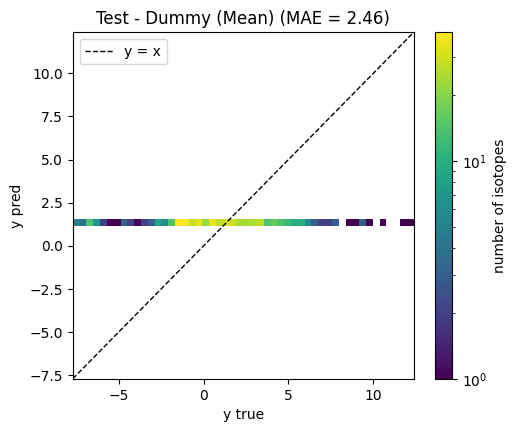

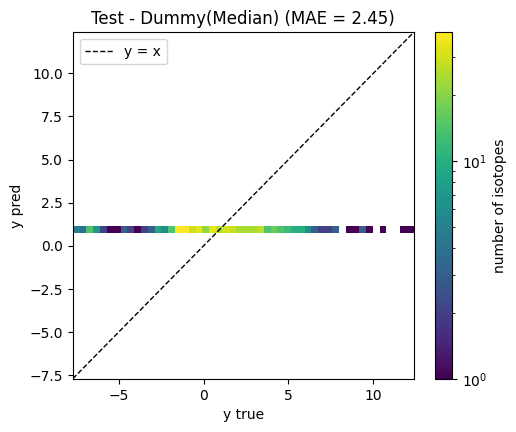

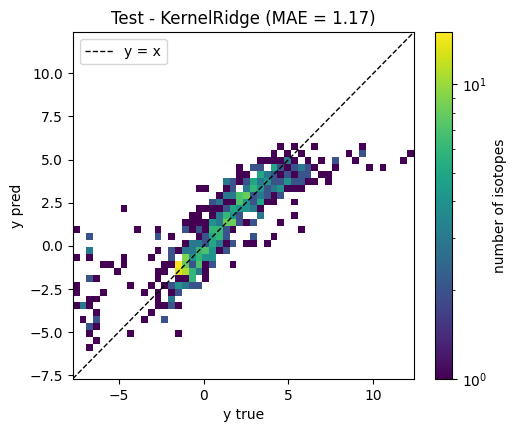

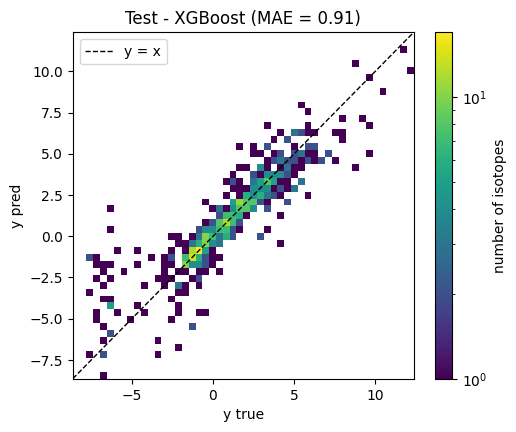

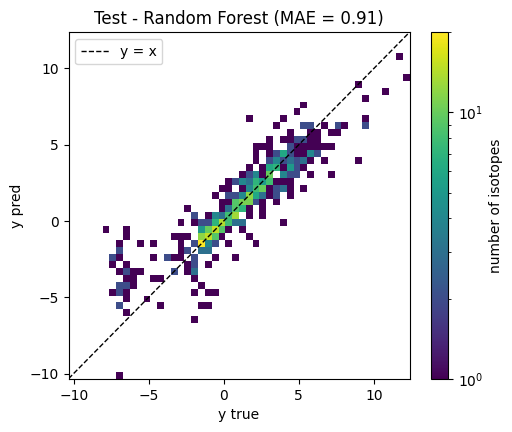

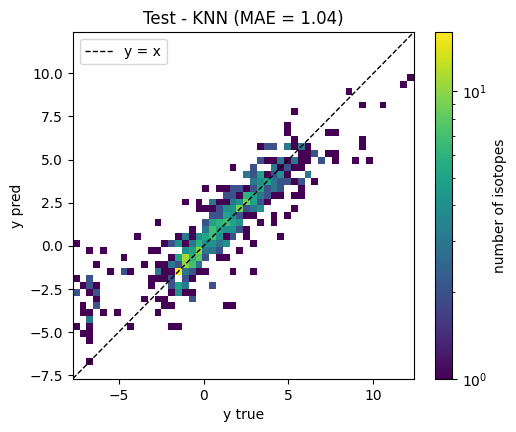

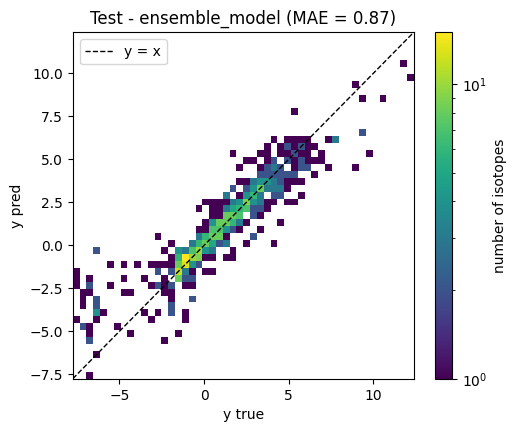

In [108]:
models = {
    'Dummy (Mean)': dummyregressor_mean,
    'Dummy(Median)': dummyregressor_median,
    'KernelRidge': krr_model2,
    'XGBoost': xgb_model2,
    'Random Forest': random_forest_model2,
    'KNN' : knn_model,
    'ensemble_model': ensemble_model
}
def hist_density(y_true, y_pred, xlabel='y true', ylabel='y pred', title=None, bins=50):
    """Parity plot drawn as a 2D histogram.

    y_true: true values
    y_pred: predicted values
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    mae = np.mean(np.abs(y_true - y_pred))

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    h = ax.hist2d(y_true, y_pred, bins=bins, range=[lims, lims], cmin=1, cmap='viridis', norm=LogNorm())
    fig.colorbar(h[3], ax=ax, label='number of isotopes')
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}")
    ax.legend(loc='upper left')
    plt.show()

for name, model in models.items():
    y_pred = model.predict(df_test[features])

    hist_density(
        df_test[TARGET],
        y_pred,
        title = f'Test - {name}'
    )

In [76]:
#results summary for top 4 performing models

results_summary_df = pd.DataFrame({
    'Kernel Ridge Regression': krr_model2_results_df.loc['Test'],
    'XGBoost': xgb_model2_results_df.loc['Test'],
    'Random Forest': rf_model2_results_df.loc['Test'],
    'ensemble_model': ensemble_model_results_df.loc['Test']
})

display(results_summary_df)

,Kernel Ridge Regression,XGBoost,Random Forest,ensemble_model
mae,1.1654,0.9149,0.9061,0.8723
mse,3.0887,2.0899,2.0023,1.8379
max_error,8.7122,8.1399,6.9156,6.2849
mape,1.1155,0.7512,0.6657,0.6891
r^2,0.7024,0.7987,0.8071,0.8229
